# 14 · RMSprop, Adam and AdamW

**Lecture:** *RMSprop, Adam and AdamW* (03-09-2026) · **Notes:** `../notes/14_rmsprop_adam_adamw.md`

Chapter 13 ended with two ideas: **momentum** (average gradients over time) and **Adagrad** (scale each parameter by its gradient history, but the history never forgets). This lecture combines them:
- **RMSprop** = Adagrad with **forgetting** (a moving average of g² instead of a sum);
- **Adam** = RMSprop + **momentum** + **bias correction**;
- **AdamW** = Adam + weight decay applied **separately** (decoupled) from the adaptive update.

In this notebook you will:
1. Write RMSprop, Adam and AdamW by hand and confirm that PyTorch computes exactly the same numbers.
2. See what **bias correction** really does on the first steps (a surprise: without it, Adam's first steps are too **big**).
3. Show that Adam's step size doesn't care about the **scale** of the gradient, and why that means "less tuning".
4. Show that `weight_decay` means **different things** in Adam and AdamW.
5. Race all of them at the "default" learning rate.

Runs in about 1 minute on a CPU.

In [1]:
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
torch.manual_seed(0)

## 1 · The three update rules, written by hand

**RMSprop** (ρ ≈ 0.9–0.99): s_t = ρ·s_{t−1} + (1 − ρ)·g_t²,  θ_t = θ_{t−1} − η·g_t / (√s_t + ε)

**Adam** (β₁ = 0.9, β₂ = 0.999):
m_t = β₁·m_{t−1} + (1 − β₁)·g_t  (first moment, momentum-like)
v_t = β₂·v_{t−1} + (1 − β₂)·g_t²  (second moment, RMSprop-like)
m̂_t = m_t / (1 − β₁ᵗ),  v̂_t = v_t / (1 − β₂ᵗ)  (bias correction)
θ_t = θ_{t−1} − η·m̂_t / (√v̂_t + ε)

**AdamW:** θ_t = θ_{t−1} − η·m̂_t / (√v̂_t + ε) **− η·λ·θ_{t−1}**

In [2]:
def loss_fn(th):                                   # an elongated bowl, steep in the 2nd coordinate
    return 0.5 * (0.5 * th[0] ** 2 + 8.0 * th[1] ** 2)
def grad_fn(th):
    return np.array([0.5 * th[0], 8.0 * th[1]])

def by_hand(method, steps=50, lr=0.05, rho=0.9, b1=0.9, b2=0.999, eps=1e-8, wd=0.0):
    th = np.array([3.0, 1.0]); s = np.zeros(2); m = np.zeros(2); v = np.zeros(2)
    for t in range(1, steps + 1):
        g = grad_fn(th)
        if method == "RMSprop":
            s = rho * s + (1 - rho) * g ** 2
            th = th - lr * g / (np.sqrt(s) + eps)
        else:
            m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g ** 2
            m_hat = m / (1 - b1 ** t); v_hat = v / (1 - b2 ** t)
            th_old = th
            th = th - lr * m_hat / (np.sqrt(v_hat) + eps)
            if method == "AdamW":
                th = th - lr * wd * th_old                     # decoupled decay on the OLD weights
    return th

def by_torch(method, steps=50, lr=0.05, wd=0.0):
    th = torch.tensor([3.0, 1.0], dtype=torch.float64, requires_grad=True)
    opt = {"RMSprop": lambda: torch.optim.RMSprop([th], lr=lr, alpha=0.9, eps=1e-8),
           "Adam": lambda: torch.optim.Adam([th], lr=lr, betas=(0.9, 0.999), eps=1e-8),
           "AdamW": lambda: torch.optim.AdamW([th], lr=lr, betas=(0.9, 0.999), eps=1e-8, weight_decay=wd)}[method]()
    for _ in range(steps):
        opt.zero_grad(); loss_fn(th).backward(); opt.step()
    return th.detach().numpy()

for method, wd in [("RMSprop", 0.0), ("Adam", 0.0), ("AdamW", 0.1)]:
    h, t_ = by_hand(method, wd=wd), by_torch(method, wd=wd)
    print(f"{method:<8} by hand {h.round(8)}   PyTorch {t_.round(8)}   max difference {np.abs(h - t_).max():.1e}")

RMSprop  by hand [0.56908961 0.        ]   PyTorch [0.56908961 0.        ]   max difference 0.0e+00
Adam     by hand [ 0.85192175 -0.037882  ]   PyTorch [ 0.85192175 -0.037882  ]   max difference 1.1e-16
AdamW    by hand [ 0.55001507 -0.02131985]   PyTorch [ 0.55001507 -0.02131985]   max difference 3.3e-16


All three agree with PyTorch to floating-point precision. So the lecture's equations are exactly what `torch.optim.RMSprop` (its ρ is called `alpha`), `Adam` and `AdamW` do.

> **Implementation detail worth knowing:** PyTorch's AdamW multiplies the weights by (1 − η·λ) **before** the Adam step; the lecture writes the decay as a separate term using θ_{t−1}. That's the same thing, as the matching numbers show.

## 2 · Bias correction: what goes wrong without it?
m and v start at **0**, so their early values are pulled towards 0. Watch the first step with a constant gradient g = 2:

In [3]:
g, b1, b2, lr = 2.0, 0.9, 0.999, 0.01
m = v = 0.0
print(f"{'step':>4} {'m':>8} {'v':>9} {'m_hat':>7} {'v_hat':>7} {'step WITH correction':>21} {'step WITHOUT':>13}")
for t in range(1, 6):
    m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g ** 2
    mh, vh = m / (1 - b1 ** t), v / (1 - b2 ** t)
    print(f"{t:>4} {m:8.4f} {v:9.5f} {mh:7.3f} {vh:7.3f} {lr * mh / math.sqrt(vh):21.4f} {lr * m / math.sqrt(v):13.4f}")
steps_uncorr = []
m = v = 0.0
for t in range(1, 2001):
    m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g ** 2; steps_uncorr.append(lr * m / math.sqrt(v))
print(f"\nwithout correction the step is {steps_uncorr[0] / lr:.2f}× η at step 1, peaks at {max(steps_uncorr) / lr:.2f}× η (step {int(np.argmax(steps_uncorr)) + 1}), and is still {steps_uncorr[499] / lr:.2f}× η at step 500")

step        m         v   m_hat   v_hat  step WITH correction  step WITHOUT
   1   0.2000   0.00400   2.000   4.000                0.0100        0.0316
   2   0.3800   0.00800   2.000   4.000                0.0100        0.0425
   3   0.5420   0.01199   2.000   4.000                0.0100        0.0495
   4   0.6878   0.01598   2.000   4.000                0.0100        0.0544
   5   0.8190   0.01996   2.000   4.000                0.0100        0.0580

without correction the step is 3.16× η at step 1, peaks at 6.57× η (step 12), and is still 1.59× η at step 500


**What bias correction really fixes:**
- With correction, m̂ = 2 and v̂ = 4 = g² from the very first step: the true values for a constant gradient. So the step is exactly **η** (0.01).
- Without it, **both** m and v are too small, but v is far more biased (β₂ = 0.999 forgets very slowly), so m/√v comes out **too large**: 3.16× η at step 1 peaking at **6.57× η** at step 12, and still 1.59× η at step 500.
- So the lecture's "early moving averages are biased toward zero" is right, and the practical consequence is **oversized, unstable early steps**, exactly when the weights are still random. Bias correction is what makes Adam safe to start.

## 3 · Why Adam needs "less tuning": its step doesn't depend on gradient scale
Same bowl, but now multiply the loss by 0.001, 1 or 1000 (as if the data had different units). Plain SGD's step is η·g, so it scales with the gradient. Adam's step is η·m̂/√v̂, and **the scale cancels**.

In [4]:
def run_scaled(opt_name, scale, lr, steps=200):
    th = torch.tensor([3.0, 1.0], requires_grad=True)
    opt = torch.optim.SGD([th], lr=lr) if opt_name == "SGD" else torch.optim.Adam([th], lr=lr)
    for _ in range(steps):
        opt.zero_grad(); (scale * loss_fn(th)).backward(); opt.step()
    return loss_fn(th.detach()).item()

print(f"{'loss scale':>10} {'SGD (lr 0.1) final loss':>24} {'Adam (lr 0.05) final loss':>26}")
for scale in [0.001, 1, 1000]:
    print(f"{scale:>10} {run_scaled('SGD', scale, 0.1):>24.4g} {run_scaled('Adam', scale, 0.05):>26.4g}")

loss scale  SGD (lr 0.1) final loss  Adam (lr 0.05) final loss
     0.001                     5.11                  1.439e-08


         1                2.765e-09                   1.44e-08


      1000                      nan                   1.44e-08


**Measured:**
- **SGD (same η = 0.1):** with the loss scaled by 0.001 it barely moved (final loss 5.11, from a start of 6.25); at scale 1 it converged; at scale 1000 it **exploded to NaN**. One η can't serve all three: SGD's η has to be re-tuned whenever the gradient scale changes.
- **Adam (η = 0.05):** the **same final loss (1.44 × 10⁻⁸) at all three scales**. Its step ≈ η × (direction), whatever the units of the loss.

That's the concrete meaning of the lecture's "**usually requires less manual learning-rate tuning**": η in Adam is roughly "how far each weight may move per step", not "multiply the gradient by this".

## 4 · RMSprop vs Adagrad: forgetting matters
Chapter 13's stall test: walk θ from 0 to 100 on L = ½(θ − 100)², η = 1.

Adagrad  θ after 50 steps  12.43, after 300 steps  31.03; first within 0.5 of 100 at step None
RMSprop  θ after 50 steps  54.08, after 300 steps 100.00; first within 0.5 of 100 at step 125
Adam     θ after 50 steps  46.32, after 300 steps  99.98; first within 0.5 of 100 at step 232


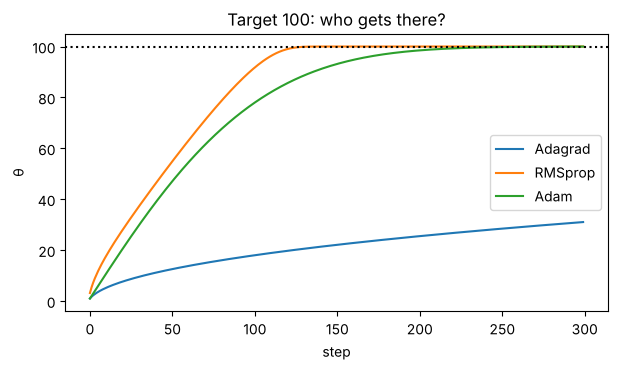

In [5]:
def walk(method, steps=300, eta=1.0, rho=0.9):
    th, G, s, m, v = 0.0, 0.0, 0.0, 0.0, 0.0; out = []
    for t in range(1, steps + 1):
        g = th - 100.0
        if method == "Adagrad":
            G += g * g; th -= eta * g / (math.sqrt(G) + 1e-8)
        elif method == "RMSprop":
            s = rho * s + (1 - rho) * g * g; th -= eta * g / (math.sqrt(s) + 1e-8)
        else:
            m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
            th -= eta * (m / (1 - 0.9 ** t)) / (math.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
        out.append(th)
    return np.array(out)
plt.figure(figsize=(7, 3.6))
for m_ in ["Adagrad", "RMSprop", "Adam"]:
    path = walk(m_); plt.plot(path, label=m_)
    first = next((i + 1 for i, x in enumerate(path) if abs(x - 100) < 0.5), None)
    print(f"{m_:<8} θ after 50 steps {path[49]:6.2f}, after 300 steps {path[-1]:6.2f}; first within 0.5 of 100 at step {first}")
plt.axhline(100, color="k", ls=":"); plt.xlabel("step"); plt.ylabel("θ"); plt.legend(); plt.title("Target 100: who gets there?"); plt.show()

- **Adagrad** stalls (θ = 31 after 300 steps): its sum of g² never forgets the huge early gradients.
- **RMSprop** reaches 100 (within 0.5 by step 125): the moving average forgets old gradients, so the step size recovers. That is the whole difference between them.
- **Adam** also gets there (step 232), a little later here, because its momentum overshoots and has to swing back. Adam isn't the fastest on every toy problem; its strength is robustness across many problems.

## 5 · Adam + L2 vs AdamW: "weight decay" means two different things

- **Adam with L2** (`torch.optim.Adam(..., weight_decay=λ)`): λθ is **added to the gradient**, so it then gets divided by √v̂ like everything else. Parameters with **large gradients** get **less** effective decay; the decay is tangled up with the adaptive scaling.
- **AdamW** (`torch.optim.AdamW(..., weight_decay=λ)`): the decay −ηλθ is applied **directly** to the weights, the same strength for every parameter, independent of its gradient history.

Same network on the digits, same λ = 0.01 for both, 40 epochs; we measure how much the weights actually shrank.

In [6]:
d = load_digits()
Xa, Xte, ya, yte = train_test_split(d.data / 16, d.target, test_size=0.25, random_state=0, stratify=d.target)
Xtr, Xva, ytr, yva = train_test_split(Xa, ya, test_size=0.2, random_state=0, stratify=ya)
T = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt)
Xtr, Xva, Xte = T(Xtr), T(Xva), T(Xte); ytr, yva, yte = T(ytr, torch.long), T(yva, torch.long), T(yte, torch.long)

def make_net(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 10))

def train(make_opt, epochs=40, seed=0, lr=1e-3):
    net = make_net(seed); opt = make_opt(net.parameters(), lr); curve = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 32):
            idx = perm[i:i + 32]; loss = F.cross_entropy(net(Xtr[idx]), ytr[idx]); opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad(): curve.append(F.cross_entropy(net(Xtr), ytr).item())
    with torch.no_grad():
        wnorm = sum(p.norm() ** 2 for n_, p in net.named_parameters() if "weight" in n_).sqrt().item()
        return curve, wnorm, (net(Xva).argmax(1) == yva).float().mean().item(), (net(Xte).argmax(1) == yte).float().mean().item()

w0 = sum(p.norm() ** 2 for n_, p in make_net(0).named_parameters() if "weight" in n_).sqrt().item()
print(f"weight norm at initialisation: {w0:.2f}\n")
for name, mk in [("Adam, no decay", lambda p, lr: torch.optim.Adam(p, lr=lr)),
                 ("Adam + L2 (weight_decay=0.01)", lambda p, lr: torch.optim.Adam(p, lr=lr, weight_decay=0.01)),
                 ("AdamW (weight_decay=0.01)", lambda p, lr: torch.optim.AdamW(p, lr=lr, weight_decay=0.01)),
                 ("AdamW (weight_decay=0.1)", lambda p, lr: torch.optim.AdamW(p, lr=lr, weight_decay=0.1)),
                 ("AdamW (weight_decay=1.0)", lambda p, lr: torch.optim.AdamW(p, lr=lr, weight_decay=1.0))]:
    res = [train(mk, seed=s) for s in range(3)]
    print(f"{name:<30} final weight norm {np.mean([r[1] for r in res]):6.2f}   test accuracy {np.mean([r[3] for r in res]):.1%} ± {np.std([r[3] for r in res]):.1%}")

weight norm at initialisation: 13.18



Adam, no decay                 final weight norm  22.09   test accuracy 98.1% ± 0.1%


Adam + L2 (weight_decay=0.01)  final weight norm   8.71   test accuracy 95.6% ± 1.6%


AdamW (weight_decay=0.01)      final weight norm  21.94   test accuracy 98.0% ± 0.0%


AdamW (weight_decay=0.1)       final weight norm  20.65   test accuracy 98.0% ± 0.2%


AdamW (weight_decay=1.0)       final weight norm  15.25   test accuracy 97.5% ± 0.6%


**Measured (3 seeds):**

| | final weight norm | test accuracy |
|---|---|---|
| Adam, no decay | 22.09 | 98.1% |
| **Adam + L2, λ = 0.01** | **8.71** | **95.6%** ± 1.6 |
| AdamW, λ = 0.01 | 21.94 | 98.0% |
| AdamW, λ = 0.1 | 20.65 | 98.0% |
| AdamW, λ = 1.0 | 15.25 | 97.5% |

- **The same number λ = 0.01 means completely different things.** In Adam + L2, the decay term λθ is divided by √v̂, and for weights whose gradients are tiny, √v̂ is tiny, so their decay is **amplified enormously**. The weights collapsed to 8.7 and accuracy dropped.
- In **AdamW** the decay is −η·λ·θ per step: with η = 0.001 and λ = 0.01 that's a 0.001% shrink per step, so λ = 0.01 barely does anything here. You need **larger** λ values (0.1–1.0) for a visible effect, and the effect is **even across parameters and predictable**.
- This is the lecture's point: AdamW makes the weight-decay hyperparameter behave "**more directly as a parameter-shrinkage control**", **independent of the adaptive scaling**. It's also why you can't copy a `weight_decay` value from an Adam setup into an AdamW setup.

## 6 · A race at the "default" learning rate 0.001
The lecture's hyperparameter table says η ≈ 0.001 for RMSprop, Adam and AdamW. What happens if we use that same η for every optimizer, with no tuning?

SGD             η = 0.001: training loss after 20 epochs 2.2752   test accuracy 25.3% ± 7.0%


SGD + momentum  η = 0.001: training loss after 20 epochs 1.5938   test accuracy 80.6% ± 0.9%


Adagrad         η = 0.001: training loss after 20 epochs 0.4287   test accuracy 91.9% ± 0.4%


RMSprop         η = 0.001: training loss after 20 epochs 0.0336   test accuracy 96.9% ± 0.4%


Adam            η = 0.001: training loss after 20 epochs 0.0206   test accuracy 97.0% ± 0.9%


AdamW           η = 0.001: training loss after 20 epochs 0.0212   test accuracy 97.0% ± 0.9%


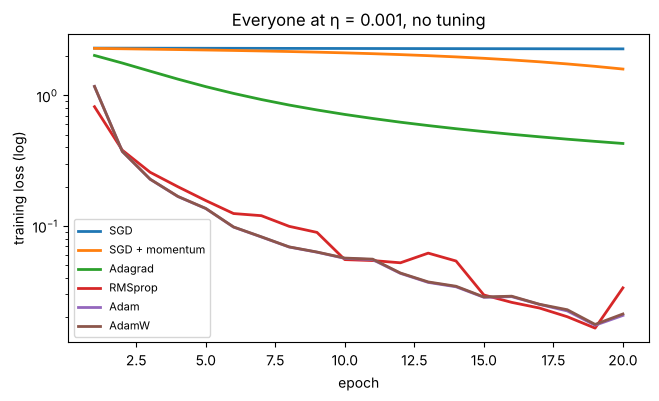

In [7]:
contenders = {
    "SGD":            lambda p, lr: torch.optim.SGD(p, lr=lr),
    "SGD + momentum": lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=0.9),
    "Adagrad":        lambda p, lr: torch.optim.Adagrad(p, lr=lr),
    "RMSprop":        lambda p, lr: torch.optim.RMSprop(p, lr=lr, alpha=0.9),
    "Adam":           lambda p, lr: torch.optim.Adam(p, lr=lr),
    "AdamW":          lambda p, lr: torch.optim.AdamW(p, lr=lr, weight_decay=0.01),
}
plt.figure(figsize=(7.5, 4))
for name, mk in contenders.items():
    res = [train(mk, epochs=20, seed=s, lr=1e-3) for s in range(3)]
    curve = np.mean([r[0] for r in res], axis=0)
    plt.semilogy(range(1, 21), curve, lw=2, label=name)
    print(f"{name:<15} η = 0.001: training loss after 20 epochs {curve[-1]:.4f}   test accuracy {np.mean([r[3] for r in res]):.1%} ± {np.std([r[3] for r in res]):.1%}")
plt.xlabel("epoch"); plt.ylabel("training loss (log)"); plt.legend(fontsize=8); plt.title("Everyone at η = 0.001, no tuning"); plt.show()

**Measured at η = 0.001 for everyone:**
- **Adam 97.0%, AdamW 97.0%, RMSprop 96.9%**: all trained well at the textbook default.
- **Adagrad 91.9%**: slower (its rate keeps shrinking).
- **SGD + momentum 80.6%**, and **plain SGD 25.3%** (its training loss barely moved from ln 10 ≈ 2.30): at η = 0.001 plain SGD is simply far too slow (chapter 13 found its best η was 0.3).

So the adaptive methods' real advantage is **robustness to the learning-rate choice**, not a higher ceiling: at their **own best** η (chapter 13), all optimizers tied. This is why Adam/AdamW with η ≈ 1e-3 is the go-to default for fast experiments.

## Summary

| | RMSprop | Adam | AdamW |
|---|---|---|---|
| main idea | moving average of g² (Adagrad that forgets) | 1st moment (momentum) + 2nd moment (scaling) + bias correction | Adam + **decoupled** weight decay |
| momentum? | no explicit first moment | yes | yes |
| adaptive per-parameter scaling? | yes | yes | yes |
| weight decay | not built in | L2 added to the gradient (**coupled**) | applied directly: −ηλθ (**decoupled**) |
| typical settings | η ≈ 0.001, ρ ≈ 0.9–0.99 | η ≈ 0.001, β₁ = 0.9, β₂ = 0.999 | the same + λ tuned explicitly (e.g. 0.01–0.1) |
| use when | a simple adaptive optimizer | a strong default for fast experiments | Transformers and modern models; when you want regularisation you can tune separately |

**Hiker analogy (lecture):** SGD looks at the current slope. RMSprop also remembers how **steep** recent slopes were and takes smaller steps where it's been steep. Adam also remembers the **direction** of recent slopes. AdamW additionally pulls all weights gently towards zero, separately from the walking.

## ✅ Check yourself
1. Adam, step 1, gradient g: what are m̂₁ and v̂₁, and what is the step size? *(m̂ = g, v̂ = g², step = η·g/|g| = η)*
2. Without bias correction, is Adam's first step too small or too large (β₁ = 0.9, β₂ = 0.999)? *(too large: 0.1g/√(0.001g²) = 3.16 η)*
3. What does RMSprop add to Adagrad? *(forgetting: a moving average of g² instead of a growing sum)*
4. Why does multiplying the loss by 1,000 barely change Adam's path? *(m̂ and √v̂ both scale by 1,000; the ratio doesn't)*
5. Adam + L2 vs AdamW: where does λθ go? *(Adam+L2: into the gradient, then divided by √v̂; AdamW: subtracted from the weights directly)*
6. Two moving averages in Adam: which is the "first moment" and which the "second"? *(m: mean of gradients; v: mean of squared gradients)*